# Data-Driven Crime Analytics in South Africa

**Student Number:** 22434665
**Surname:** Sibiya
**Initials:** AN SIBIYA

**Module:** Technical Programming 2
**Programming Language:** Python
**Project:** Machine Learning-Based Crime Analytics


## 1. Introduction

Crime analysis involves examining crime data to identify patterns, trends and areas that may require additional attention. Large datasets containing crime incidents, geographic information and demographic characteristics can be analysed using data analytics and machine learning techniques.

This project develops a data-driven crime analytics solution using crime incident data and station-level contextual information. The project applies data preprocessing, feature engineering, exploratory data analysis, machine learning classification, model validation, clustering and time-series forecasting.

The classification component will identify stations that can be considered crime hotspots. Logistic Regression, Decision Tree and Random Forest models will be developed and compared using appropriate evaluation metrics and confusion matrices. Clustering will then be used to identify groups of stations with similar characteristics, while forecasting will be used to estimate future crime levels.

The final solution will also include a Streamlit dashboard and a drone simulation that demonstrates how identified crime hotspots could be used as points of interest for drone route planning.


## 1.1 Problem Statement

Crime datasets can contain large numbers of records across different locations, time periods and crime categories. Analysing these records manually can make it difficult to identify high-crime areas, understand historical patterns and anticipate future crime levels.

The problem addressed by this project is to develop a data-driven solution that can analyse crime incidents, identify potential crime hotspots, group similar stations and forecast future crime activity. The solution should provide useful information that can support data-driven decision-making and allocation of resources.


## 1.2 Project Objectives

The objectives of this project are to:

1. Acquire and examine crime and station-level datasets.
2. Clean and preprocess the datasets.
3. Integrate the related datasets using a common identifier.
4. Perform feature engineering to create meaningful variables for analysis.
5. Perform exploratory data analysis to identify crime patterns and trends.
6. Develop a machine learning classification model for identifying crime hotspots.
7. Implement Logistic Regression, Decision Tree and Random Forest models.
8. Validate the machine learning models using appropriate validation techniques.
9. Evaluate the models using accuracy, precision, recall, F1-score and confusion matrices.
10. Compare the performance of the classification models.
11. Apply K-Means clustering to identify groups of similar stations.
12. Perform time-series forecasting of future crime incidents.
13. Develop a Streamlit dashboard to present the analysis and results.
14. Develop a drone programming simulation based on identified crime hotspots.
15. Analyse the computational complexity of selected algorithms and operations.


# Import Libraries

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning - data splitting and validation
from sklearn.model_selection import train_test_split, cross_val_score

# Machine learning - preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Machine learning - classification
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Machine learning - clustering
from sklearn.cluster import KMeans

# Machine learning - evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error
)

# Warnings
import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
#Python Version

In [3]:
import sys

print("Python version:")
print(sys.version)

Python version:
3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


## 2. Data Acquisition

Two related datasets are used for this project.

### Dataset 1: Station Context Dataset

This dataset contains information about crime stations and their surrounding characteristics, including population, geographical area, province, urban type, taxi-rank availability and unemployment rate.

### Dataset 2: Crime Incident Dataset

This dataset contains monthly crime information for each station. It includes the station identifier, month, crime category and number of incidents.

### Relationship Between the Datasets

The two datasets are related through the `station_id` field. Dataset 1 contains station-level information, while Dataset 2 contains multiple crime records for each station across different months and crime categories.

Combining these datasets allows crime incidents to be analysed together with demographic, geographic and socioeconomic characteristics.


# Loading Datasets

In [4]:
station_df = pd.read_csv("fictional_stations.csv")

station_df.head()

,station_id,station_name,province,urban_type,population,area_km2,has_taxi_rank,unemployment_rate
0,ST001,Pearl Heights,KwaZulu-Natal,Rural,12819,1758.2,1,0.313
1,ST002,Cedar Junction,Free State,Town,48186,164.8,1,0.260
2,ST003,Lotus Gardens,Eastern Cape,Metro,155464,76.0,1,0.245
3,ST004,Eagle Junction,KwaZulu-Natal,Rural,18071,2151.2,1,0.538
4,ST005,Dune Hills,Western Cape,Metro,175816,68.8,1,0.317


In [5]:
crime_df = pd.read_csv("fictional_crime_monthly.csv")

crime_df.head()

,station_id,month,category,incidents
0,ST001,2019-01,Theft of motor vehicle,3.0
1,ST001,2019-02,Theft of motor vehicle,3.0
2,ST001,2019-03,Theft of motor vehicle,2.0
3,ST001,2019-04,Theft of motor vehicle,2.0
4,ST001,2019-05,Theft of motor vehicle,2.0


## 3. Data Understanding

The data understanding stage is used to examine the structure, size, data types and statistical characteristics of the datasets before preprocessing. This helps identify potential data-quality issues such as missing values, duplicate records and incorrect data types.


In [6]:
print("Station dataset shape:", station_df.shape)
print("Crime dataset shape:", crime_df.shape)

Station dataset shape: (120, 8)
Crime dataset shape: (34580, 4)


In [7]:
# Inspecting Dataset Information

In [8]:
print("STATION DATASET")
station_df.info()

print("\nCRIME DATASET")
crime_df.info()

STATION DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   station_id         120 non-null    object 
 1   station_name       120 non-null    object 
 2   province           120 non-null    object 
 3   urban_type         120 non-null    object 
 4   population         120 non-null    int64  
 5   area_km2           120 non-null    float64
 6   has_taxi_rank      120 non-null    int64  
 7   unemployment_rate  120 non-null    float64
dtypes: float64(2), int64(2), object(4)
memory usage: 7.6+ KB

CRIME DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34580 entries, 0 to 34579
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   station_id  34580 non-null  object 
 1   month       34580 non-null  object 
 2   category    34580 non-null  object 
 3   incid

In [9]:
# Statistical Summary

In [10]:
print("Station dataset:")
display(station_df.describe())

print("\nCrime dataset:")
display(crime_df.describe())

Station dataset:


,population,area_km2,has_taxi_rank,unemployment_rate
count,120.000000,120.000000,120.000000,120.000000
mean,62476.258333,536.465833,0.533333,0.363875
std,52791.684963,684.908398,0.500979,0.089975
min,4940.000000,5.000000,0.000000,0.173000
25%,21136.000000,72.475000,0.000000,0.304500
50%,46271.000000,213.000000,1.000000,0.353500
75%,87035.500000,872.000000,1.000000,0.428250
max,217761.000000,2592.800000,1.000000,0.573000



Crime dataset:


,incidents
count,34539.000000
mean,36.628623
std,54.091865
min,0.000000
25%,4.000000
50%,14.000000
75%,41.000000
max,371.000000


### 3.1 Missing Values

Missing values are checked in both datasets to determine whether records contain incomplete information that could affect subsequent analysis and machine learning models.


In [13]:
print("Missing values in station dataset:")
print(station_df.isnull().sum())

print("\nMissing values in crime dataset:")
print(crime_df.isnull().sum())

Missing values in station dataset:
station_id           0
station_name         0
province             0
urban_type           0
population           0
area_km2             0
has_taxi_rank        0
unemployment_rate    0
dtype: int64

Missing values in crime dataset:
station_id     0
month          0
category       0
incidents     41
dtype: int64


### 3.2 Duplicate Records

Duplicate records are identified to determine whether the datasets contain repeated observations that could incorrectly influence the analysis.


In [14]:
print("Duplicate rows in station dataset:",
      station_df.duplicated().sum())

print("Duplicate rows in crime dataset:",
      crime_df.duplicated().sum())

Duplicate rows in station dataset: 0
Duplicate rows in crime dataset: 20


In [15]:
#Checking Station IDs

In [16]:
print("Unique station IDs in station dataset:",
      station_df["station_id"].nunique())

print("Unique station IDs in crime dataset:",
      crime_df["station_id"].nunique())

Unique station IDs in station dataset: 120
Unique station IDs in crime dataset: 120


In [17]:
crime_station_ids = set(crime_df["station_id"])
station_ids = set(station_df["station_id"])

unmatched_ids = crime_station_ids - station_ids

print("Unmatched station IDs:", unmatched_ids)

Unmatched station IDs: set()


In [18]:
# Understanding Categorical Variables

In [19]:
print(station_df["province"].value_counts())

province
Gauteng          27
Western Cape     17
Eastern Cape     16
KwaZulu-Natal    14
Mpumalanga       12
Free State       11
Limpopo          10
North West        8
Northern Cape     5
Name: count, dtype: int64


In [20]:
print(station_df["urban_type"].value_counts())

urban_type
Town     49
Metro    37
Rural    34
Name: count, dtype: int64


In [21]:
print(station_df["has_taxi_rank"].value_counts())

has_taxi_rank
1    64
0    56
Name: count, dtype: int64


In [22]:
print(crime_df["category"].value_counts())

category
Carjacking                          8648
Theft out of motor vehicle          8647
Theft of motor vehicle              8643
Burglary at residential premises    8642
Name: count, dtype: int64


In [23]:
# Understanding Time Variable

In [24]:
print("First month:", crime_df["month"].min())
print("Last month:", crime_df["month"].max())

print("Number of unique months:",
      crime_df["month"].nunique())

First month: 2019-01
Last month: 2024-12
Number of unique months: 72


## 4. Data Processing

Data Processing is performed to improve the quality and consistency of the datasets before analysis and machine learning. Based on the data-understanding stage, the crime dataset contains duplicate records and missing incident values. The `month` variable also needs to be converted into a datetime format so that time-based analysis and forecasting can be performed correctly.

The station dataset does not contain missing values or duplicate records and therefore requires minimal cleaning.


In [25]:
# Creating Clean Copies

In [26]:
station_clean = station_df.copy()
crime_clean = crime_df.copy()

print("Clean copies created.")

Clean copies created.


In [27]:
# Removing Duplicate Crime Records

In [28]:
before_duplicates = len(crime_clean)

crime_clean = crime_clean.drop_duplicates()

after_duplicates = len(crime_clean)

print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Rows before removing duplicates: 34580
Rows after removing duplicates: 34560
Duplicates removed: 20


In [29]:
# Handling Missing Incident Values

In [30]:
before_missing = len(crime_clean)

crime_clean = crime_clean.dropna(
    subset=["incidents"]
)

after_missing = len(crime_clean)

print("Rows before handling missing incidents:", before_missing)
print("Rows after handling missing incidents:", after_missing)
print("Rows removed:", before_missing - after_missing)

Rows before handling missing incidents: 34560
Rows after handling missing incidents: 34520
Rows removed: 40


In [31]:
# Converting Month to Datetime

In [32]:
crime_clean["month"] = pd.to_datetime(
    crime_clean["month"],
    format="%Y-%m"
)

In [33]:
print(crime_clean["month"].dtype)

datetime64[ns]


In [34]:
# Extracting Year and Month

In [35]:
crime_clean["year"] = crime_clean["month"].dt.year
crime_clean["month_number"] = crime_clean["month"].dt.month

In [36]:
crime_clean[
    ["month", "year", "month_number"]
].head()

,month,year,month_number
0,2019-01-01,2019,1
1,2019-02-01,2019,2
2,2019-03-01,2019,3
3,2019-04-01,2019,4
4,2019-05-01,2019,5


In [37]:
# Verifying Cleaned Dataset

In [38]:
print("Station dataset shape:", station_clean.shape)
print("Crime dataset shape:", crime_clean.shape)

print("\nMissing values:")
print(crime_clean.isnull().sum())

print("\nDuplicate rows:")
print(crime_clean.duplicated().sum())

Station dataset shape: (120, 8)
Crime dataset shape: (34520, 6)

Missing values:
station_id      0
month           0
category        0
incidents       0
year            0
month_number    0
dtype: int64

Duplicate rows:
0


### 4.1 Data Integration

The cleaned crime and station datasets are integrated using `station_id` as the common key. A left join is used so that every cleaned crime record is retained while the corresponding station-level contextual information is added.


In [39]:
merged_df = crime_clean.merge(
    station_clean,
    on="station_id",
    how="left"
)


In [40]:
print("Merged dataset shape:", merged_df.shape)

Merged dataset shape: (34520, 13)


In [41]:
print(merged_df.shape)
print(merged_df.columns.tolist())

(34520, 13)
['station_id', 'month', 'category', 'incidents', 'year', 'month_number', 'station_name', 'province', 'urban_type', 'population', 'area_km2', 'has_taxi_rank', 'unemployment_rate']


In [42]:
merged_df.head()

,station_id,month,category,incidents,year,month_number,station_name,province,urban_type,population,area_km2,has_taxi_rank,unemployment_rate
0,ST001,2019-01-01,Theft of motor vehicle,3.0,2019,1,Pearl Heights,KwaZulu-Natal,Rural,12819,1758.2,1,0.313
1,ST001,2019-02-01,Theft of motor vehicle,3.0,2019,2,Pearl Heights,KwaZulu-Natal,Rural,12819,1758.2,1,0.313
2,ST001,2019-03-01,Theft of motor vehicle,2.0,2019,3,Pearl Heights,KwaZulu-Natal,Rural,12819,1758.2,1,0.313
3,ST001,2019-04-01,Theft of motor vehicle,2.0,2019,4,Pearl Heights,KwaZulu-Natal,Rural,12819,1758.2,1,0.313
4,ST001,2019-05-01,Theft of motor vehicle,2.0,2019,5,Pearl Heights,KwaZulu-Natal,Rural,12819,1758.2,1,0.313


In [61]:
print(
    "Missing station names after merge:",
    merged_df["station_name"].isnull().sum()
)

Missing station names after merge: 0


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is used to understand the structure, distribution and patterns within the cleaned crime data before feature engineering and machine-learning modelling.

The analysis examines crime categories, geographic patterns, trends over time, station-level crime levels and relationships between variables. Visualisations and summary statistics are used to identify patterns that can guide the subsequent feature-engineering and modelling stages.


In [62]:
# Crime by Category

In [63]:
category_crime = (
    crime_clean
    .groupby("category")["incidents"]
    .sum()
    .sort_values(ascending=False)
)

print(category_crime)

category
Burglary at residential premises    548680.0
Theft out of motor vehicle          400401.0
Theft of motor vehicle              251067.0
Carjacking                           64190.0
Name: incidents, dtype: float64


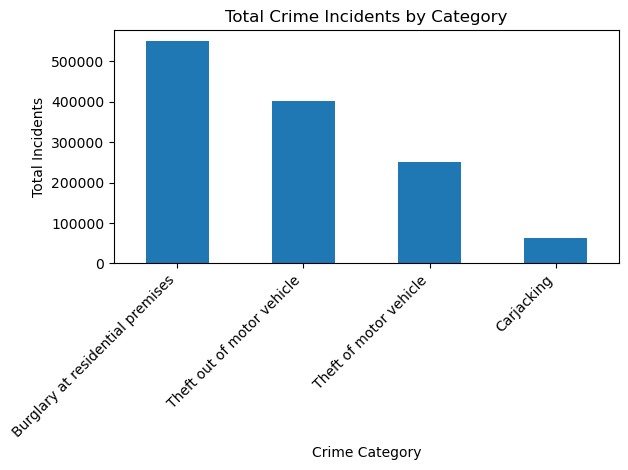

In [64]:
import matplotlib.pyplot as plt

category_crime.plot(kind="bar")

plt.title("Total Crime Incidents by Category")
plt.xlabel("Crime Category")
plt.ylabel("Total Incidents")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [65]:
# Crime by Province

In [66]:
province_crime = (
    merged_df
    .groupby("province")["incidents"]
    .sum()
    .sort_values(ascending=False)
)

print(province_crime)

province
Gauteng          296299.0
Western Cape     262649.0
Eastern Cape     214429.0
Free State       130220.0
Mpumalanga       129620.0
KwaZulu-Natal     73376.0
North West        62764.0
Northern Cape     48315.0
Limpopo           46666.0
Name: incidents, dtype: float64


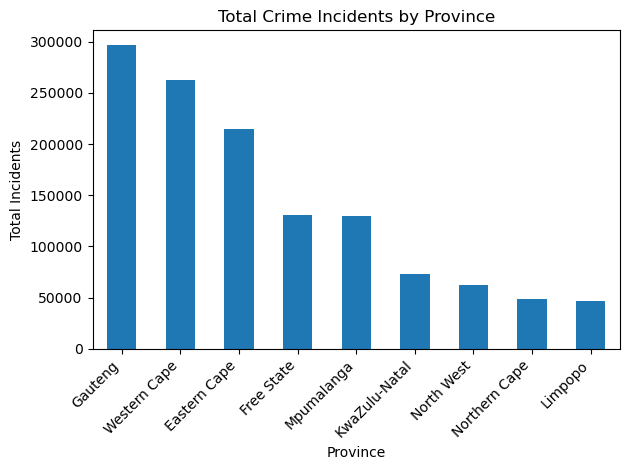

In [67]:
province_crime.plot(kind="bar")

plt.title("Total Crime Incidents by Province")
plt.xlabel("Province")
plt.ylabel("Total Incidents")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [68]:
#Crime Trend Over Time

In [69]:
yearly_crime = (
    crime_clean
    .groupby("year")["incidents"]
    .sum()
)

print(yearly_crime)

year
2019    212223.0
2020    190483.0
2021    214162.0
2022    215045.0
2023    215790.0
2024    216635.0
Name: incidents, dtype: float64


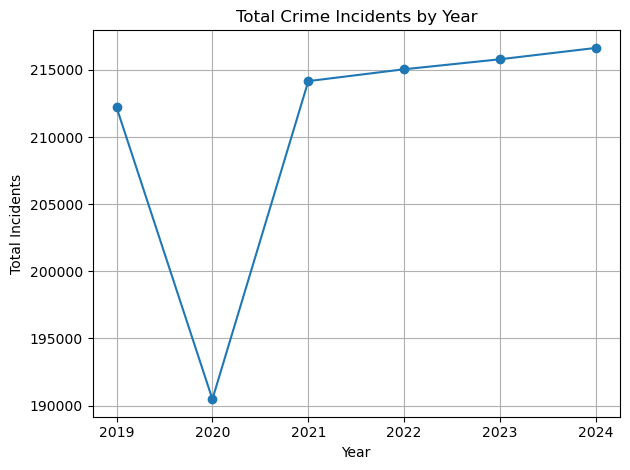

In [70]:
yearly_crime.plot(kind="line", marker="o")

plt.title("Total Crime Incidents by Year")
plt.xlabel("Year")
plt.ylabel("Total Incidents")
plt.grid(True)
plt.tight_layout()
plt.show()

In [71]:
#Monthly Crime Trend

In [72]:
monthly_crime = (
    crime_clean
    .groupby("month")["incidents"]
    .sum()
)

print(monthly_crime.head())

month
2019-01-01    16579.0
2019-02-01    16041.0
2019-03-01    16989.0
2019-04-01    16107.0
2019-05-01    16594.0
Name: incidents, dtype: float64


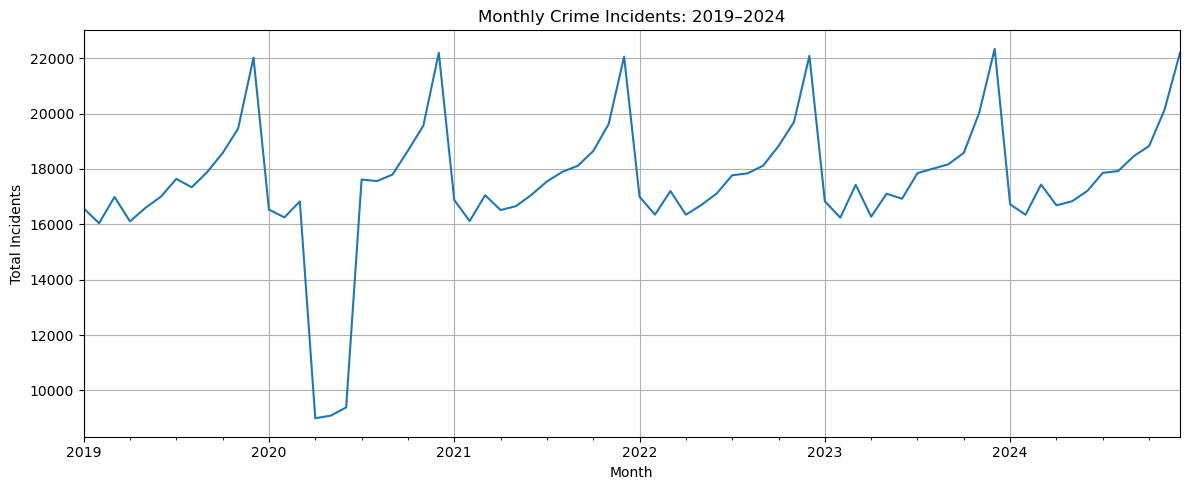

In [73]:
monthly_crime.plot(figsize=(12, 5))

plt.title("Monthly Crime Incidents: 2019–2024")
plt.xlabel("Month")
plt.ylabel("Total Incidents")
plt.grid(True)
plt.tight_layout()
plt.show()

In [74]:
# Crime Distribution by Urban Type

In [75]:
urban_crime = (
    merged_df
    .groupby("urban_type")["incidents"]
    .sum()
    .sort_values(ascending=False)
)

print(urban_crime)

urban_type
Metro    982661.0
Town     248930.0
Rural     32747.0
Name: incidents, dtype: float64


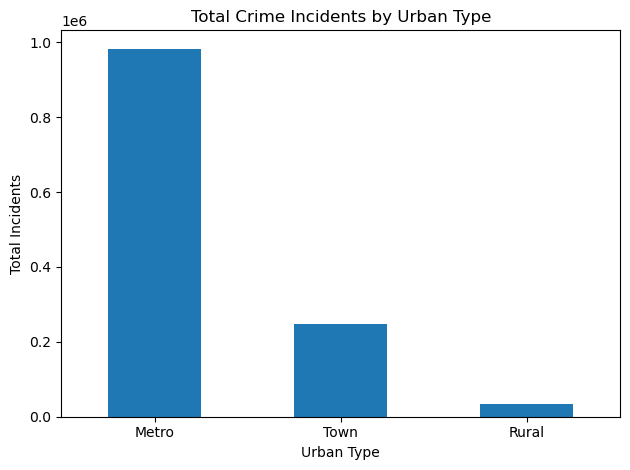

In [76]:
urban_crime.plot(kind="bar")

plt.title("Total Crime Incidents by Urban Type")
plt.xlabel("Urban Type")
plt.ylabel("Total Incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [77]:
# Top Stations by Total Crime

In [78]:
station_totals = (
    merged_df
    .groupby(["station_id", "station_name"])["incidents"]
    .sum()
    .sort_values(ascending=False)
)

print(station_totals.head(10))

station_id  station_name 
ST009       Onyx Hills       48682.0
ST087       Maple Plains     44347.0
ST101       Tulip Gardens    42222.0
ST012       Ridge Hills      40805.0
ST115       Jade Park        38923.0
ST005       Dune Hills       38888.0
ST006       Aurora Plains    34980.0
ST080       Iris Central     34311.0
ST102       Iris Bay         32825.0
ST003       Lotus Gardens    32555.0
Name: incidents, dtype: float64


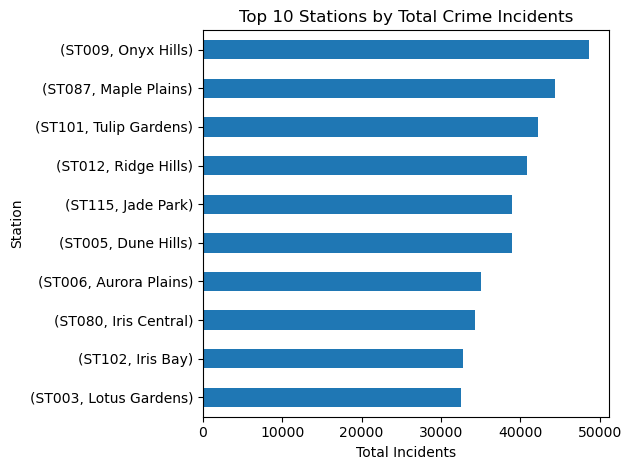

In [79]:
station_totals.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Stations by Total Crime Incidents")
plt.xlabel("Total Incidents")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

### EDA Summary

The exploratory analysis identified several patterns in the crime dataset. Burglary at residential premises recorded the highest number of incidents among the four crime categories, while carjacking recorded the lowest. Crime incidents varied considerably across provinces and urban types.

The yearly analysis showed a decrease in total incidents in 2020 followed by a recovery from 2021 onwards. The monthly analysis provides a more detailed view of changes over time and will support the later forecasting task.

The station-level analysis also showed that crime is not evenly distributed across stations. However, total incidents alone do not account for differences in population or geographic area. Therefore, additional derived measures such as crime rate and crime density will be created during the feature-engineering stage.


## 6. Feature Engineering

Feature engineering involves creating meaningful variables from the available data to improve the analysis and machine-learning process.

For the crime hotspot classification task, station-level crime measures will be created by aggregating monthly incidents and combining them with population, geographic and socioeconomic information. Crime rate and crime density will be calculated to provide population- and area-adjusted measures of crime. A hotspot target variable will then be created using a percentile-based threshold.


In [80]:
# Creating Station-Level Dataset

In [81]:
station_crime = (
    merged_df
    .groupby(["station_id", "station_name"])["incidents"]
    .sum()
    .reset_index()
)

print("Shape:", station_crime.shape)

station_crime.head()

Shape: (120, 3)


,station_id,station_name,incidents
0,ST001,Pearl Heights,907.0
1,ST002,Cedar Junction,6241.0
2,ST003,Lotus Gardens,32555.0
3,ST004,Eagle Junction,1386.0
4,ST005,Dune Hills,38888.0


In [82]:
# Adding Station Contextual Information

In [83]:
station_crime = station_crime.merge(
    station_clean[
        [
            "station_id",
            "population",
            "province",
            "urban_type",
            "area_km2",
            "has_taxi_rank",
            "unemployment_rate"
        ]
    ],
    on="station_id",
    how="left"
)

print("Shape:", station_crime.shape)

station_crime.head()

Shape: (120, 9)


,station_id,station_name,incidents,population,province,urban_type,area_km2,has_taxi_rank,unemployment_rate
0,ST001,Pearl Heights,907.0,12819,KwaZulu-Natal,Rural,1758.2,1,0.313
1,ST002,Cedar Junction,6241.0,48186,Free State,Town,164.8,1,0.260
2,ST003,Lotus Gardens,32555.0,155464,Eastern Cape,Metro,76.0,1,0.245
3,ST004,Eagle Junction,1386.0,18071,KwaZulu-Natal,Rural,2151.2,1,0.538
4,ST005,Dune Hills,38888.0,175816,Western Cape,Metro,68.8,1,0.317


In [84]:
# Creating Crime Rate

In [85]:
station_crime["crime_rate"] = (
    station_crime["incidents"]
    / station_crime["population"]
) * 100000

station_crime[
    [
        "station_id",
        "station_name",
        "incidents",
        "population",
        "crime_rate"
    ]
].head()

,station_id,station_name,incidents,population,crime_rate
0,ST001,Pearl Heights,907.0,12819,7075.434901
1,ST002,Cedar Junction,6241.0,48186,12951.894741
2,ST003,Lotus Gardens,32555.0,155464,20940.539289
3,ST004,Eagle Junction,1386.0,18071,7669.747109
4,ST005,Dune Hills,38888.0,175816,22118.578514


In [86]:
# Creating Crime Density

In [87]:
station_crime["crime_density"] = (
    station_crime["incidents"]
    / station_crime["area_km2"]
)

station_crime[
    [
        "station_id",
        "station_name",
        "incidents",
        "area_km2",
        "crime_density"
    ]
].head()

,station_id,station_name,incidents,area_km2,crime_density
0,ST001,Pearl Heights,907.0,1758.2,0.515869
1,ST002,Cedar Junction,6241.0,164.8,37.870146
2,ST003,Lotus Gardens,32555.0,76.0,428.355263
3,ST004,Eagle Junction,1386.0,2151.2,0.644292
4,ST005,Dune Hills,38888.0,68.8,565.232558


In [88]:
# Creating Hotspot Threshold

In [89]:
hotspot_threshold = station_crime["crime_rate"].quantile(0.75)

print("Hotspot threshold:", hotspot_threshold)

Hotspot threshold: 19775.8144339811


In [90]:
# Creating Hotspot Target

In [91]:
station_crime["hotspot"] = (
    station_crime["crime_rate"] >= hotspot_threshold
).astype(int)

station_crime[
    [
        "station_id",
        "station_name",
        "crime_rate",
        "hotspot"
    ]
].head()

,station_id,station_name,crime_rate,hotspot
0,ST001,Pearl Heights,7075.434901,0
1,ST002,Cedar Junction,12951.894741,0
2,ST003,Lotus Gardens,20940.539289,1
3,ST004,Eagle Junction,7669.747109,0
4,ST005,Dune Hills,22118.578514,1


In [92]:
# Checking Hotspot Distribution

In [93]:
hotspot_counts = station_crime["hotspot"].value_counts().sort_index()

print(hotspot_counts)

hotspot
0    90
1    30
Name: count, dtype: int64


In [94]:
# Checking Final Feature-Engineered Dataset

In [95]:
print("Shape:", station_crime.shape)

print("\nColumns:")
print(station_crime.columns.tolist())

print("\nMissing values:")
print(station_crime.isnull().sum())

station_crime.head()

Shape: (120, 12)

Columns:
['station_id', 'station_name', 'incidents', 'population', 'province', 'urban_type', 'area_km2', 'has_taxi_rank', 'unemployment_rate', 'crime_rate', 'crime_density', 'hotspot']

Missing values:
station_id           0
station_name         0
incidents            0
population           0
province             0
urban_type           0
area_km2             0
has_taxi_rank        0
unemployment_rate    0
crime_rate           0
crime_density        0
hotspot              0
dtype: int64


,station_id,station_name,incidents,population,province,urban_type,area_km2,has_taxi_rank,unemployment_rate,crime_rate,crime_density,hotspot
0,ST001,Pearl Heights,907.0,12819,KwaZulu-Natal,Rural,1758.2,1,0.313,7075.434901,0.515869,0
1,ST002,Cedar Junction,6241.0,48186,Free State,Town,164.8,1,0.260,12951.894741,37.870146,0
2,ST003,Lotus Gardens,32555.0,155464,Eastern Cape,Metro,76.0,1,0.245,20940.539289,428.355263,1
3,ST004,Eagle Junction,1386.0,18071,KwaZulu-Natal,Rural,2151.2,1,0.538,7669.747109,0.644292,0
4,ST005,Dune Hills,38888.0,175816,Western Cape,Metro,68.8,1,0.317,22118.578514,565.232558,1


In [96]:
# Checking Hotspot Stations

In [97]:
hotspot_stations = (
    station_crime[
        station_crime["hotspot"] == 1
    ]
    .sort_values("crime_rate", ascending=False)
)

hotspot_stations[
    [
        "station_id",
        "station_name",
        "province",
        "crime_rate",
        "crime_density",
        "hotspot"
    ]
].head(10)

,station_id,station_name,province,crime_rate,crime_density,hotspot
32,ST033,Kestrel Valley,Free State,23733.725651,216.508577,1
48,ST049,Fern Valley,Western Cape,23536.517883,401.049137,1
51,ST052,Jade Hills,Gauteng,23482.441757,5499.400000,1
47,ST048,Aurora Hills,Mpumalanga,23365.792251,1126.919643,1
75,ST076,Tulip Rand,Gauteng,23213.757396,512.826797,1
25,ST026,Pearl Bay,North West,22515.346609,361.490385,1
10,ST011,Cedar Central,Free State,22511.993752,155.510597,1
70,ST071,Pearl Gardens,Eastern Cape,22487.012122,479.573864,1
5,ST006,Aurora Plains,Western Cape,22425.233195,658.757062,1
8,ST009,Onyx Hills,Gauteng,22355.701893,590.084848,1


### Feature Engineering Summary

The monthly crime records were aggregated to create a station-level dataset containing total recorded incidents for each police station. Contextual variables including population, geographic area, urban type, taxi-rank availability and unemployment rate were then integrated into the station-level dataset.

Two derived measures were created: crime rate per 100,000 population and crime density per square kilometre. A hotspot target was created using the 75th percentile of station crime rates as the classification threshold. Stations at or above this threshold were classified as hotspots, resulting in 30 hotspots and 90 non-hotspots.

Crime rate and crime density are retained for analysis, but they will not be used as predictors in the initial hotspot classification model because they are derived from the crime incidents used to define the hotspot target and could introduce data leakage.


## 7. Machine Learning Modelling

Machine-learning classification models will be developed to predict whether a police station is a crime hotspot. The target variable is the binary `hotspot` variable, where 1 represents a hotspot and 0 represents a non-hotspot.

Contextual demographic, geographic and socioeconomic variables will be used as predictors. Variables directly used to construct the hotspot target, such as crime rate, total incidents and crime density, will be excluded from the predictors to reduce the risk of data leakage.


In [98]:
# Creating X and y

In [99]:
X = station_crime[
    [
        "population",
        "area_km2",
        "has_taxi_rank",
        "unemployment_rate",
        "province",
        "urban_type"
    ]
]

y = station_crime["hotspot"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (120, 6)
Target shape: (120,)

Features:
['population', 'area_km2', 'has_taxi_rank', 'unemployment_rate', 'province', 'urban_type']

Target distribution:
hotspot
0    90
1    30
Name: count, dtype: int64


In [100]:
# Identifying Numerical and Categorical Features

In [101]:
numeric_features = [
    "population",
    "area_km2",
    "has_taxi_rank",
    "unemployment_rate"
]

categorical_features = [
    "province",
    "urban_type"
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['population', 'area_km2', 'has_taxi_rank', 'unemployment_rate']
Categorical features: ['province', 'urban_type']


In [102]:
# Train/Test Split

In [103]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (96, 6)
Testing features: (24, 6)

Training target distribution:
hotspot
0    72
1    24
Name: count, dtype: int64

Testing target distribution:
hotspot
0    18
1     6
Name: count, dtype: int64


In [104]:
# Processing Pipeline

In [105]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


###  Logistic Regression

Logistic Regression is a supervised classification algorithm used to predict a binary outcome. In this project, it will be used to predict whether a police station is classified as a crime hotspot (`1`) or a non-hotspot (`0`).

The model will be implemented using a pipeline that combines feature preprocessing with Logistic Regression. This ensures that numerical and categorical variables are processed consistently before classification.


In [106]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


In [109]:
# Training model

In [110]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [111]:
# Making predictions

In [112]:
y_pred_logistic = logistic_model.predict(X_test)

print("Predictions:")
print(y_pred_logistic)

Predictions:
[0 0 0 1 0 0 1 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1]


In [113]:
# Evaluating Logistic Regression

In [114]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
precision_logistic = precision_score(y_test, y_pred_logistic)
recall_logistic = recall_score(y_test, y_pred_logistic)
f1_logistic = f1_score(y_test, y_pred_logistic)

print("Logistic Regression Results")
print("----------------------------")
print("Accuracy :", accuracy_logistic)
print("Precision:", precision_logistic)
print("Recall   :", recall_logistic)
print("F1 Score :", f1_logistic)

Logistic Regression Results
----------------------------
Accuracy : 0.9583333333333334
Precision: 0.8571428571428571
Recall   : 1.0
F1 Score : 0.9230769230769231


In [115]:
# Classification report

In [116]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97        18
           1       0.86      1.00      0.92         6

    accuracy                           0.96        24
   macro avg       0.93      0.97      0.95        24
weighted avg       0.96      0.96      0.96        24



In [117]:
# Confusion matrix

In [118]:
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

print("Logistic Regression Confusion Matrix:")
print(cm_logistic)

Logistic Regression Confusion Matrix:
[[17  1]
 [ 0  6]]


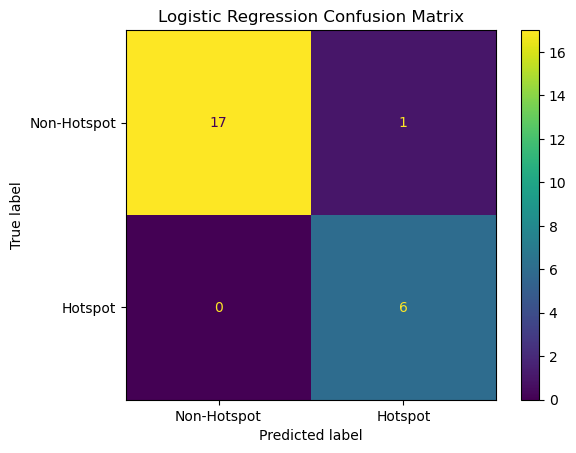

In [119]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Non-Hotspot", "Hotspot"]
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

### Logistic Regression Interpretation

The Logistic Regression model achieved an accuracy of 95.83% on the test set. The model correctly classified 23 out of 24 police stations.

The model achieved a precision of 85.71%, recall of 100% and F1-score of 92.31% for the hotspot classification task. The confusion matrix contained 17 true negatives, 1 false positive, 0 false negatives and 6 true positives.

The 100% recall indicates that all actual hotspot stations in the test set were successfully identified. This is important for crime hotspot detection because missing an actual hotspot may be more undesirable than incorrectly classifying a non-hotspot as a hotspot.

Although the model performed strongly, it is not perfect because one non-hotspot station was incorrectly classified as a hotspot. Further models will be tested to determine whether classification performance can be improved.


###  Decision Tree

A Decision Tree is a supervised machine-learning algorithm that makes predictions by applying a sequence of decision rules to the input features. The resulting structure resembles a tree, with decision nodes, branches and leaf nodes.

In this project, a Decision Tree will be used to classify police stations as crime hotspots or non-hotspots based on demographic, geographic and socioeconomic features.


In [120]:
# Creating Decision Tree pipeline

In [121]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

print("Decision Tree pipeline created successfully.")

Decision Tree pipeline created successfully.


In [122]:
# Training model

In [123]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [124]:
# Making predictions

In [125]:
y_pred_tree = decision_tree_model.predict(X_test)

print("Decision Tree Predictions:")
print(y_pred_tree)

Decision Tree Predictions:
[0 0 0 1 0 0 1 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1]


In [126]:
# Evaluating Decision Tree

In [127]:
accuracy_tree = accuracy_score(y_test, y_pred_tree)
precision_tree = precision_score(y_test, y_pred_tree)
recall_tree = recall_score(y_test, y_pred_tree)
f1_tree = f1_score(y_test, y_pred_tree)

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", accuracy_tree)
print("Precision:", precision_tree)
print("Recall   :", recall_tree)
print("F1 Score :", f1_tree)

Decision Tree Results
---------------------
Accuracy : 0.9583333333333334
Precision: 0.8571428571428571
Recall   : 1.0
F1 Score : 0.9230769230769231


In [129]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97        18
           1       0.86      1.00      0.92         6

    accuracy                           0.96        24
   macro avg       0.93      0.97      0.95        24
weighted avg       0.96      0.96      0.96        24



In [130]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

print("Decision Tree Confusion Matrix:")
print(cm_tree)

Decision Tree Confusion Matrix:
[[17  1]
 [ 0  6]]


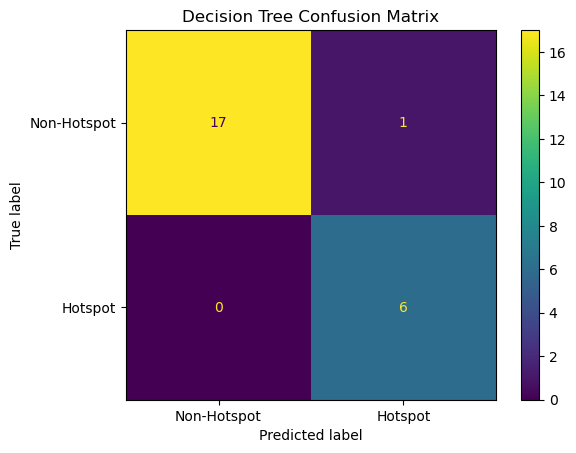

In [131]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=["Non-Hotspot", "Hotspot"]
).plot()

plt.title("Decision Tree Confusion Matrix")
plt.show()

### Decision Tree Interpretation

The Decision Tree model achieved an accuracy of 95.83% on the test set, correctly classifying 23 out of 24 police stations. The model achieved a precision of 85.71%, recall of 100% and F1-score of 92.31%.

The confusion matrix contained 17 true negatives, 1 false positive, 0 false negatives and 6 true positives. Therefore, the model successfully identified all actual hotspot stations in the test set.

The Decision Tree produced the same predictions and evaluation metrics as the Logistic Regression model on the current test set. Although the two algorithms use different classification approaches, they produced identical results for this particular dataset and train-test split. A Random Forest model will be tested next to determine whether an ensemble approach can provide improved performance.


### Random Forest

Random Forest is an ensemble machine-learning algorithm that combines the predictions of multiple Decision Trees. Each tree is trained using different subsets of the data and features, and the final prediction is determined by combining the predictions of the individual trees.

Random Forest is used in this project to determine whether an ensemble model can improve the classification of crime hotspots compared with Logistic Regression and a single Decision Tree.


In [132]:
# Creating Random Forest pipeline

In [133]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]
)

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [134]:
# Training model

In [135]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [136]:
# Make predictions

In [137]:
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest Predictions:")
print(y_pred_rf)

Random Forest Predictions:
[0 0 0 1 0 0 1 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1]


In [138]:
 #Evaluating Random Forest

In [139]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1 Score :", f1_rf)

Random Forest Results
---------------------
Accuracy : 0.9583333333333334
Precision: 0.8571428571428571
Recall   : 1.0
F1 Score : 0.9230769230769231


In [140]:
# Classification report

In [141]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97        18
           1       0.86      1.00      0.92         6

    accuracy                           0.96        24
   macro avg       0.93      0.97      0.95        24
weighted avg       0.96      0.96      0.96        24



In [142]:
# Confusion matrix

In [143]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[17  1]
 [ 0  6]]


In [144]:
#Visualizing confusion matrix

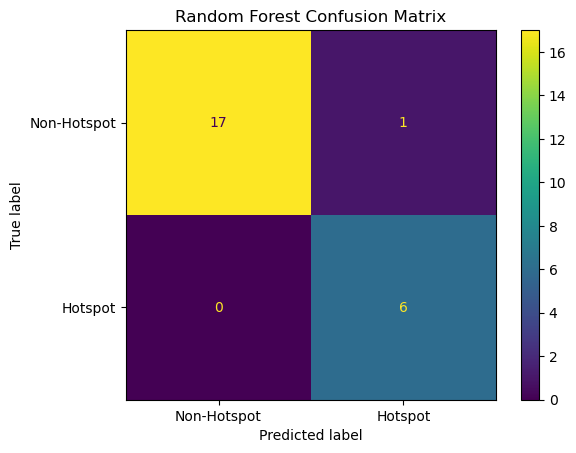

In [145]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Non-Hotspot", "Hotspot"]
).plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

##  Classification Model Comparison

Three supervised classification algorithms were tested for crime hotspot prediction: Logistic Regression, Decision Tree and Random Forest.

All three models were evaluated using the same training and testing datasets. This provides a fair comparison because each model is evaluated on the same 24 unseen test stations.

The models produced identical results on the test set, achieving an accuracy of 95.83%, precision of 85.71%, recall of 100% and F1-score of 92.31%. Each model produced 17 true negatives, 1 false positive, 0 false negatives and 6 true positives.

Although the models performed identically on the current test set, their underlying algorithms are different. Logistic Regression models the relationship between predictors and the probability of a class, Decision Tree uses a sequence of decision rules, while Random Forest combines multiple decision trees.

Because test-set performance alone may not provide a sufficiently reliable estimate of generalisation performance, cross-validation will be used in the Model Validation section.


## 8. Model Validation

Model validation is used to determine how well a machine-learning model is likely to perform on unseen data. Instead of relying only on one train-test split, cross-validation evaluates the model across multiple subsets of the training data.

Stratified K-Fold Cross-Validation will be used because the hotspot target contains two classes with an unequal distribution. Stratification helps maintain a similar class distribution in each fold.

The three classification models will be evaluated using five-fold cross-validation and their accuracy scores will be compared.


In [146]:
# Creating Cross-Validation Strategy

In [147]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold stratified cross-validation created.")

5-fold stratified cross-validation created.


In [148]:
# Validating Logistic Regression

In [149]:
logistic_cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Logistic Regression Cross-Validation Scores:")
print(logistic_cv_scores)

print("\nMean Accuracy:", logistic_cv_scores.mean())
print("Standard Deviation:", logistic_cv_scores.std())

Logistic Regression Cross-Validation Scores:
[1. 1. 1. 1. 1.]

Mean Accuracy: 1.0
Standard Deviation: 0.0


In [150]:
# Validating Decision Tree

In [151]:
tree_cv_scores = cross_val_score(
    decision_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Decision Tree Cross-Validation Scores:")
print(tree_cv_scores)

print("\nMean Accuracy:", tree_cv_scores.mean())
print("Standard Deviation:", tree_cv_scores.std())

Decision Tree Cross-Validation Scores:
[1.         0.94736842 1.         1.         1.        ]

Mean Accuracy: 0.9894736842105264
Standard Deviation: 0.02105263157894739


In [152]:
# Validating Random Forest

In [153]:
rf_cv_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Random Forest Cross-Validation Scores:")
print(rf_cv_scores)

print("\nMean Accuracy:", rf_cv_scores.mean())
print("Standard Deviation:", rf_cv_scores.std())

Random Forest Cross-Validation Scores:
[1.         0.94736842 1.         1.         1.        ]

Mean Accuracy: 0.9894736842105264
Standard Deviation: 0.02105263157894739


### Model Validation Results

Five-fold Stratified Cross-Validation was used to assess the consistency of the three classification models.

Logistic Regression achieved a mean cross-validation accuracy of 100.00% with a standard deviation of 0.00%. All five validation folds achieved 100% accuracy.

Decision Tree achieved a mean accuracy of 98.95% with a standard deviation of approximately 2.11%. Four folds achieved 100% accuracy, while one fold achieved approximately 94.74%.

Random Forest produced the same cross-validation results as the Decision Tree, with a mean accuracy of 98.95% and a standard deviation of approximately 2.11%.

Based on cross-validation accuracy and consistency, Logistic Regression produced the strongest validation performance among the three models. However, the results should be interpreted cautiously because the practice dataset contains only 120 stations.


In [154]:
# Creating a Model Validation Comparison Table

In [155]:
cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Mean CV Accuracy": [
        logistic_cv_scores.mean(),
        tree_cv_scores.mean(),
        rf_cv_scores.mean()
    ],
    "Standard Deviation": [
        logistic_cv_scores.std(),
        tree_cv_scores.std(),
        rf_cv_scores.std()
    ]
})

cv_results

,Model,Mean CV Accuracy,Standard Deviation
0,Logistic Regression,1.000000,0.000000
1,Decision Tree,0.989474,0.021053
2,Random Forest,0.989474,0.021053


In [156]:
# Comparing Test-Set Results

In [157]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_tree,
        accuracy_rf
    ],
    "Precision": [
        precision_logistic,
        precision_tree,
        precision_rf
    ],
    "Recall": [
        recall_logistic,
        recall_tree,
        recall_rf
    ],
    "F1 Score": [
        f1_logistic,
        f1_tree,
        f1_rf
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.958333,0.857143,1.0,0.923077
1,Decision Tree,0.958333,0.857143,1.0,0.923077
2,Random Forest,0.958333,0.857143,1.0,0.923077


## 9. Model Evaluation & Comparison

The classification models are evaluated using accuracy, precision, recall and F1-score on the unseen test data. Cross-validation results are also considered to assess how consistently each model performs across different subsets of the training data.

For crime hotspot detection, recall is particularly important because a false negative represents an actual hotspot that the model failed to identify. The models will therefore be compared using both their overall performance and their ability to detect hotspot stations.


In [158]:
# Displaying Test-Set Comparison

In [159]:
model_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.958333,0.857143,1.0,0.923077
1,Decision Tree,0.958333,0.857143,1.0,0.923077
2,Random Forest,0.958333,0.857143,1.0,0.923077


In [160]:
cv_results

,Model,Mean CV Accuracy,Standard Deviation
0,Logistic Regression,1.000000,0.000000
1,Decision Tree,0.989474,0.021053
2,Random Forest,0.989474,0.021053


In [161]:
# Visualise Model Performance

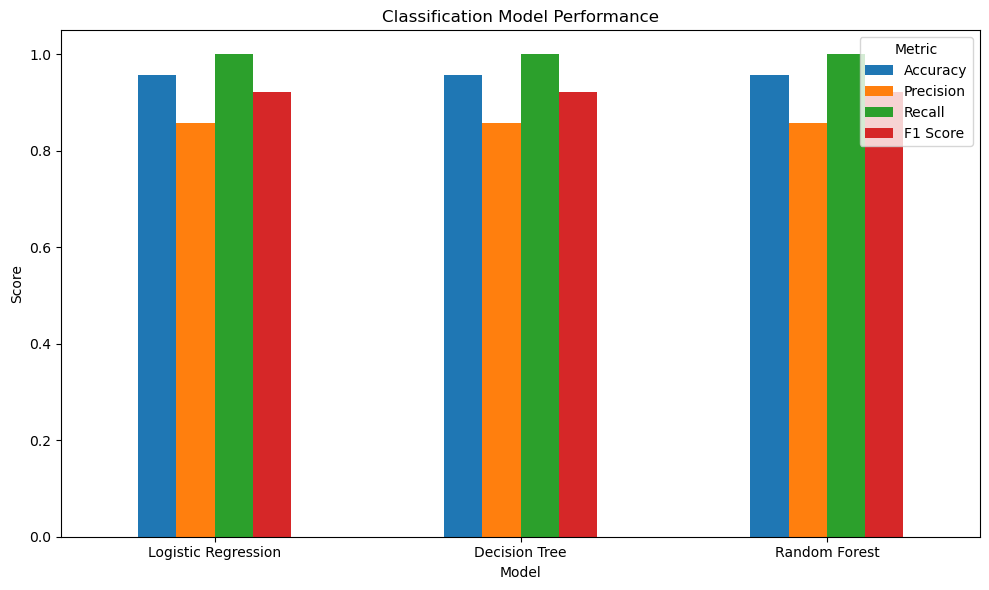

In [162]:
import matplotlib.pyplot as plt

model_results_plot = model_results.set_index("Model")

model_results_plot[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Classification Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [163]:
# Selecting Best Model

In [164]:
best_model_name = cv_results.loc[
    cv_results["Mean CV Accuracy"].idxmax(),
    "Model"
]

print("Selected model:", best_model_name)

Selected model: Logistic Regression


###  Model Evaluation Conclusion

All three classification models achieved identical performance on the test set, with an accuracy of 95.83%, precision of 85.71%, recall of 100% and F1-score of 92.31%.

Cross-validation provided additional information about model consistency. Logistic Regression achieved a mean cross-validation accuracy of 100% with a standard deviation of 0%, while both Decision Tree and Random Forest achieved a mean accuracy of approximately 98.95% with a standard deviation of approximately 2.11%.

Based on the combination of test-set performance, hotspot recall and cross-validation consistency, Logistic Regression is selected as the current preferred classification model for the crime hotspot prediction task.


## 10. Model Improvement

Model improvement involves testing alternative model configurations to determine whether predictive performance can be improved. Hyperparameter tuning will be applied to the selected Logistic Regression model.

The regularisation parameter `C` will be tested using cross-validation. Different values of `C` control the strength of regularisation and can affect how the model generalises to unseen data.


In [165]:
# Hyperparameter Tuning

In [167]:
from sklearn.model_selection import GridSearchCV

logistic_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    logistic_model,
    param_grid=logistic_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

print("Best parameters:", logistic_grid.best_params_)
print("Best cross-validation accuracy:", logistic_grid.best_score_)

Best parameters: {'classifier__C': 1}
Best cross-validation accuracy: 1.0


In [168]:
# Evaluating Tuned Model

In [169]:
tuned_logistic_model = logistic_grid.best_estimator_

y_pred_tuned = tuned_logistic_model.predict(X_test)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)

print("Tuned Logistic Regression Results")
print("----------------------------------")
print("Accuracy :", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall   :", recall_tuned)
print("F1 Score :", f1_tuned)

Tuned Logistic Regression Results
----------------------------------
Accuracy : 0.9583333333333334
Precision: 0.8571428571428571
Recall   : 1.0
F1 Score : 0.9230769230769231


In [170]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

print("\nTuned Logistic Regression Confusion Matrix:")
print(cm_tuned)


Tuned Logistic Regression Confusion Matrix:
[[17  1]
 [ 0  6]]


In [171]:
# Classification Report for Tuned Model

In [172]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97        18
           1       0.86      1.00      0.92         6

    accuracy                           0.96        24
   macro avg       0.93      0.97      0.95        24
weighted avg       0.96      0.96      0.96        24



###  Model Improvement Results

Hyperparameter tuning was performed on the Logistic Regression model by testing different values of the regularisation parameter `C`.

The best parameter was `C = 1`, which produced a cross-validation accuracy of 100%. This is also the default value used in the original Logistic Regression model.

The tuned model achieved the same test-set results as the original model: 95.83% accuracy, 85.71% precision, 100% recall and 92.31% F1-score. The confusion matrix remained unchanged, with 17 true negatives, 1 false positive, 0 false negatives and 6 true positives.

Therefore, hyperparameter tuning did not improve the model on the current dataset. The original Logistic Regression configuration is retained as the preferred classification model because it provides strong performance without requiring additional model complexity.


## 11. Clustering

Clustering is an unsupervised machine-learning technique used to group observations based on similarities in their characteristics. Unlike classification, clustering does not require a predefined target variable.

K-Means clustering will be used to identify groups of police stations with similar crime and contextual characteristics. This can help identify station profiles that may have similar patterns of crime activity, population characteristics and geographic conditions.


In [173]:
# Selecting Clustering Features

In [174]:
cluster_features = station_crime[
    [
        "population",
        "area_km2",
        "unemployment_rate",
        "incidents",
        "crime_rate",
        "crime_density"
    ]
].copy()

print("Clustering dataset shape:", cluster_features.shape)
print("\nClustering features:")
print(cluster_features.columns.tolist())

Clustering dataset shape: (120, 6)

Clustering features:
['population', 'area_km2', 'unemployment_rate', 'incidents', 'crime_rate', 'crime_density']


In [175]:
# Standardise the Clustering Data

In [176]:
from sklearn.preprocessing import StandardScaler

cluster_scaler = StandardScaler()

cluster_scaled = cluster_scaler.fit_transform(cluster_features)

print("Clustering features standardised successfully.")
print("Scaled data shape:", cluster_scaled.shape)

Clustering features standardised successfully.
Scaled data shape: (120, 6)


In [177]:
# Determining a Suitable Number of Clusters

In [178]:
from sklearn.cluster import KMeans

inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(cluster_scaled)
    inertia.append(kmeans.inertia_)

print("Inertia values:")
print(inertia)

Inertia values:
[361.01570244595456, 223.99435688904575, 149.83753589970328, 127.81860631397855, 114.81543061305612, 100.34933600550224, 92.40895417524126, 81.85806591835882, 74.80835937603797]


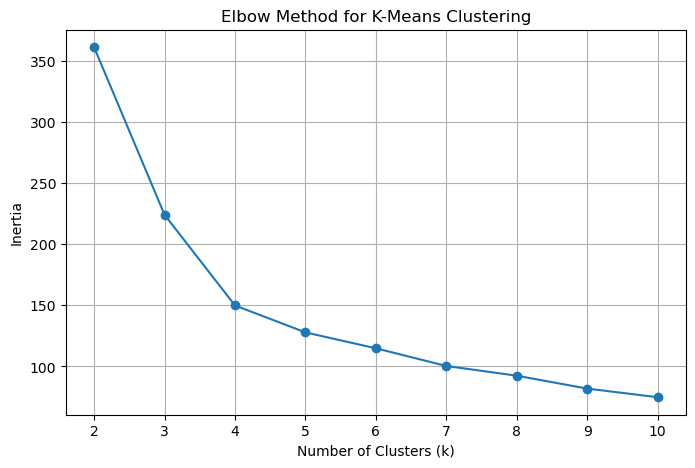

In [179]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [180]:
# Creating the K-Means Model

In [181]:
kmeans_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(cluster_scaled)

print("K-Means clustering completed successfully.")
print("Cluster labels:")
print(cluster_labels)

K-Means clustering completed successfully.
Cluster labels:
[0 2 1 0 1 1 1 1 1 1 2 3 2 2 2 2 2 2 0 1 1 1 2 2 2 1 2 2 1 0 1 0 1 0 0 0 0
 0 2 0 1 2 2 0 2 2 2 1 1 2 2 3 2 2 2 2 2 1 0 0 2 2 2 0 2 0 2 2 1 0 1 2 0 1
 2 1 0 1 0 1 0 0 2 0 0 0 1 2 1 2 1 2 2 2 2 0 0 2 2 0 1 1 1 2 2 0 2 2 0 0 2
 2 2 1 1 0 2 2 0 2]


In [182]:
station_crime["cluster"] = cluster_labels

print("Cluster labels added to station_crime.")
print("\nCluster distribution:")
print(station_crime["cluster"].value_counts().sort_index())

Cluster labels added to station_crime.

Cluster distribution:
cluster
0    33
1    32
2    53
3     2
Name: count, dtype: int64


In [183]:
cluster_summary = (
    station_crime
    .groupby("cluster")[
        [
            "population",
            "area_km2",
            "unemployment_rate",
            "incidents",
            "crime_rate",
            "crime_density"
        ]
    ]
    .mean()
    .round(2)
)

cluster_summary

,population,area_km2,unemployment_rate,incidents,crime_rate,crime_density
cluster,,,,,,
0,17506.85,1539.47,0.46,975.21,5526.16,0.70
1,134680.16,61.39,0.29,27770.03,20672.88,532.78
2,43494.08,218.71,0.35,5192.70,11692.74,48.87
3,152237.00,8.60,0.34,34151.00,22629.64,4422.04


In [184]:
cluster_hotspots = (
    station_crime
    .groupby("cluster")["hotspot"]
    .agg(
        total_stations="count",
        hotspots="sum"
    )
)

cluster_hotspots["hotspot_percentage"] = (
    cluster_hotspots["hotspots"]
    / cluster_hotspots["total_stations"]
) * 100

cluster_hotspots.round(2)

,total_stations,hotspots,hotspot_percentage
cluster,,,
0,33,0,0.00
1,32,27,84.38
2,53,1,1.89
3,2,2,100.00


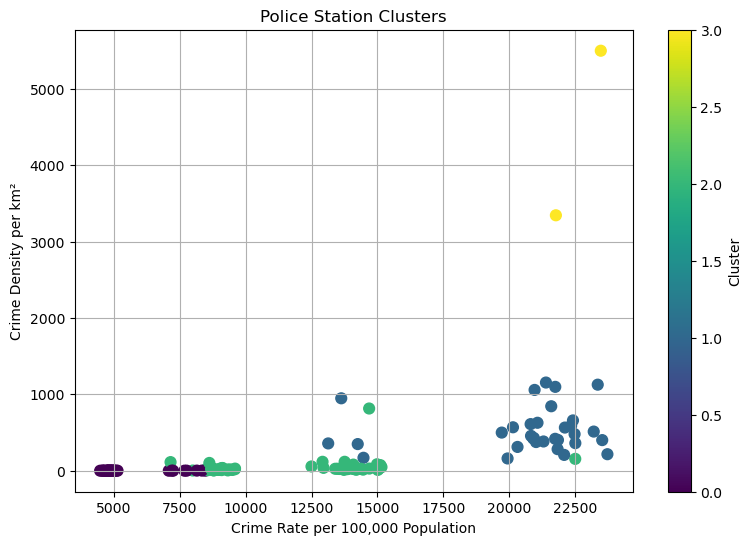

In [185]:
plt.figure(figsize=(9, 6))

plt.scatter(
    station_crime["crime_rate"],
    station_crime["crime_density"],
    c=station_crime["cluster"],
    cmap="viridis",
    s=60
)

plt.xlabel("Crime Rate per 100,000 Population")
plt.ylabel("Crime Density per km²")
plt.title("Police Station Clusters")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

## 12. Forecasting

Time-series forecasting is used to estimate future values based on historical observations. In this project, monthly crime incidents will be analysed to forecast the expected level of crime for the following 12 months.

The forecasting model will use the historical monthly crime totals from 2019 to 2024. Holt-Winters Exponential Smoothing will be used because it can model the level, trend and seasonal behaviour of a time series.

A 12-month forecast will be generated together with prediction intervals to communicate uncertainty around the forecasts.


In [186]:
forecast_data = (
    crime_clean
    .groupby("month")["incidents"]
    .sum()
    .sort_index()
)

forecast_data = forecast_data.asfreq("MS")

print("Time-series length:", len(forecast_data))
print("\nStart date:", forecast_data.index.min())
print("End date:", forecast_data.index.max())
print("\nMissing values:", forecast_data.isna().sum())

Time-series length: 72

Start date: 2019-01-01 00:00:00
End date: 2024-12-01 00:00:00

Missing values: 0


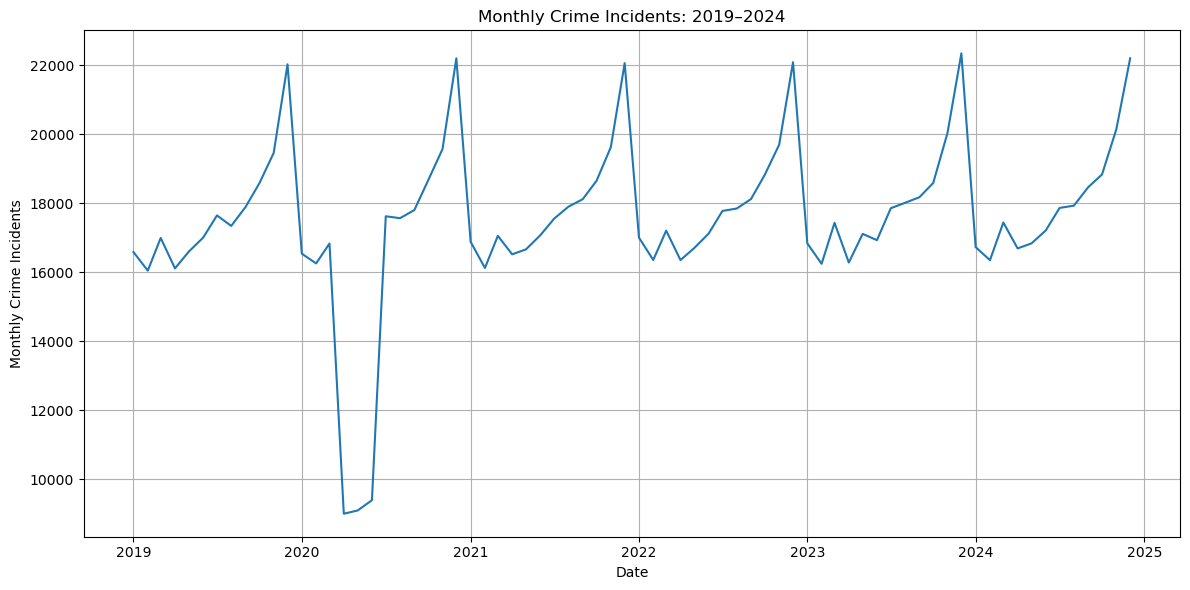

In [187]:
plt.figure(figsize=(12, 6))

plt.plot(
    forecast_data.index,
    forecast_data.values
)

plt.xlabel("Date")
plt.ylabel("Monthly Crime Incidents")
plt.title("Monthly Crime Incidents: 2019–2024")
plt.grid(True)
plt.tight_layout()
plt.show()

In [188]:
train_ts = forecast_data.iloc[:-12]
test_ts = forecast_data.iloc[-12:]

print("Training observations:", len(train_ts))
print("Testing observations:", len(test_ts))

print("\nTraining period:")
print(train_ts.index.min(), "to", train_ts.index.max())

print("\nTesting period:")
print(test_ts.index.min(), "to", test_ts.index.max())

Training observations: 60
Testing observations: 12

Training period:
2019-01-01 00:00:00 to 2023-12-01 00:00:00

Testing period:
2024-01-01 00:00:00 to 2024-12-01 00:00:00


In [189]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

holt_winters_model = ExponentialSmoothing(
    train_ts,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

print("Holt-Winters model fitted successfully.")

Holt-Winters model fitted successfully.


In [190]:
test_forecast = holt_winters_model.forecast(12)

print("Forecast for the test period:")
print(test_forecast)

Forecast for the test period:
2024-01-01    16971.434174
2024-02-01    16454.314238
2024-03-01    17195.578940
2024-04-01    14824.852037
2024-05-01    15034.752988
2024-06-01    15415.764754
2024-07-01    17653.325649
2024-08-01    17833.931201
2024-09-01    18117.709071
2024-10-01    18720.027186
2024-11-01    19723.885247
2024-12-01    22139.142523
Freq: MS, dtype: float64


In [191]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test_ts, test_forecast)

rmse = np.sqrt(
    mean_squared_error(test_ts, test_forecast)
)

print("Forecast Evaluation")
print("--------------------")
print("MAE :", mae)
print("RMSE:", rmse)

Forecast Evaluation
--------------------
MAE : 605.4815681495235
RMSE: 930.1422553905836


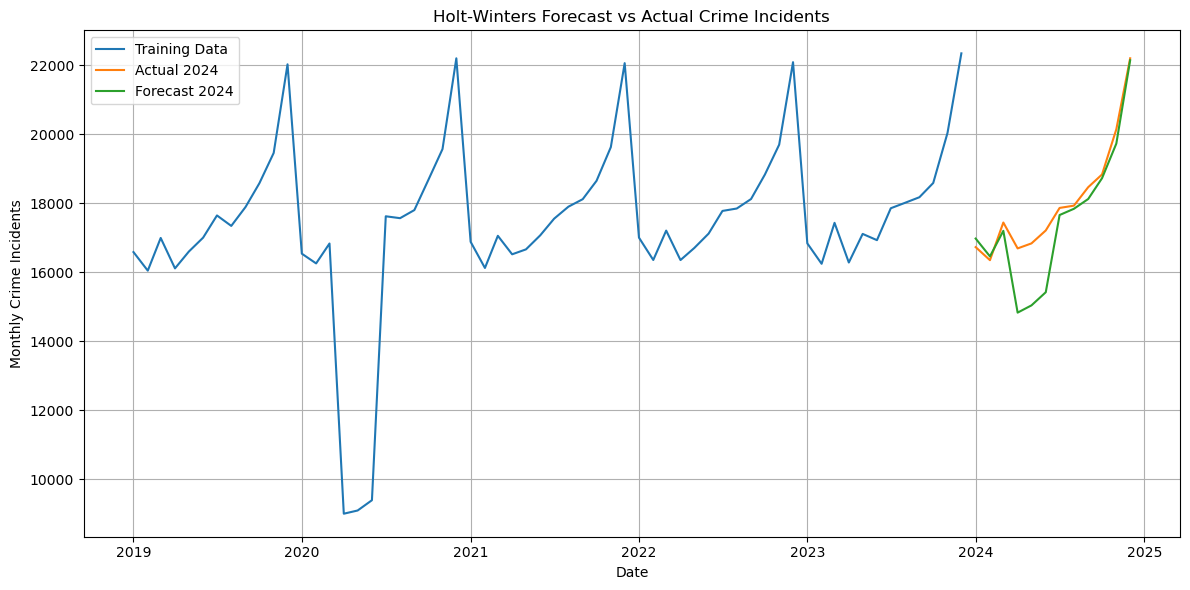

In [192]:
plt.figure(figsize=(12,6))

plt.plot(train_ts.index, train_ts.values, label="Training Data")
plt.plot(test_ts.index, test_ts.values, label="Actual 2024")
plt.plot(test_forecast.index, test_forecast.values, label="Forecast 2024")

plt.xlabel("Date")
plt.ylabel("Monthly Crime Incidents")
plt.title("Holt-Winters Forecast vs Actual Crime Incidents")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [193]:
final_holt_winters = ExponentialSmoothing(
    forecast_data,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

future_forecast = final_holt_winters.forecast(12)

print("12-Month Future Crime Forecast:")
print(future_forecast)

12-Month Future Crime Forecast:
2025-01-01    16773.969725
2025-02-01    16238.393213
2025-03-01    16857.961770
2025-04-01    14644.146585
2025-05-01    14683.204093
2025-06-01    15152.008321
2025-07-01    17145.149821
2025-08-01    17372.953352
2025-09-01    17665.939183
2025-10-01    18160.273723
2025-11-01    19207.056557
2025-12-01    21533.397539
Freq: MS, dtype: float64


In [200]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarimax_model = SARIMAX(
    forecast_data,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 0, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_result = sarimax_model.fit(
    disp=False,
    maxiter=200
)

print("SARIMAX model fitted successfully.")

SARIMAX model fitted successfully.


In [201]:
sarimax_forecast = sarimax_result.get_forecast(steps=12)

forecast_mean = sarimax_forecast.predicted_mean
forecast_ci = sarimax_forecast.conf_int()

print("12-Month Crime Forecast:")
print(forecast_mean)

12-Month Crime Forecast:
2025-01-01    16833.495516
2025-02-01    16397.515341
2025-03-01    17561.755502
2025-04-01    16634.226104
2025-05-01    17119.223177
2025-06-01    17230.961480
2025-07-01    18018.703258
2025-08-01    18131.097381
2025-09-01    18486.435212
2025-10-01    18877.374031
2025-11-01    20256.896355
2025-12-01    22433.531584
Freq: MS, Name: predicted_mean, dtype: float64


In [202]:
forecast_table = pd.DataFrame({
    "Forecast": forecast_mean,
    "Lower CI": forecast_ci.iloc[:, 0],
    "Upper CI": forecast_ci.iloc[:, 1]
})

print(forecast_table)

                Forecast      Lower CI      Upper CI
2025-01-01  16833.495516  14821.564482  18845.426550
2025-02-01  16397.515341  13959.950593  18835.080088
2025-03-01  17561.755502  14926.662496  20196.848508
2025-04-01  16634.226104  13886.230569  19382.221639
2025-05-01  17119.223177  14295.644525  19942.801828
2025-06-01  17230.961480  14350.061205  20111.861756
2025-07-01  18018.703258  15090.118604  20947.287912
2025-08-01  18131.097381  15160.224640  21101.970122
2025-09-01  18486.435212  15476.454617  21496.415807
2025-10-01  18877.374031  15830.256723  21924.491340
2025-11-01  20256.896355  17173.933408  23339.859301
2025-12-01  22433.531584  19315.622881  25551.440287


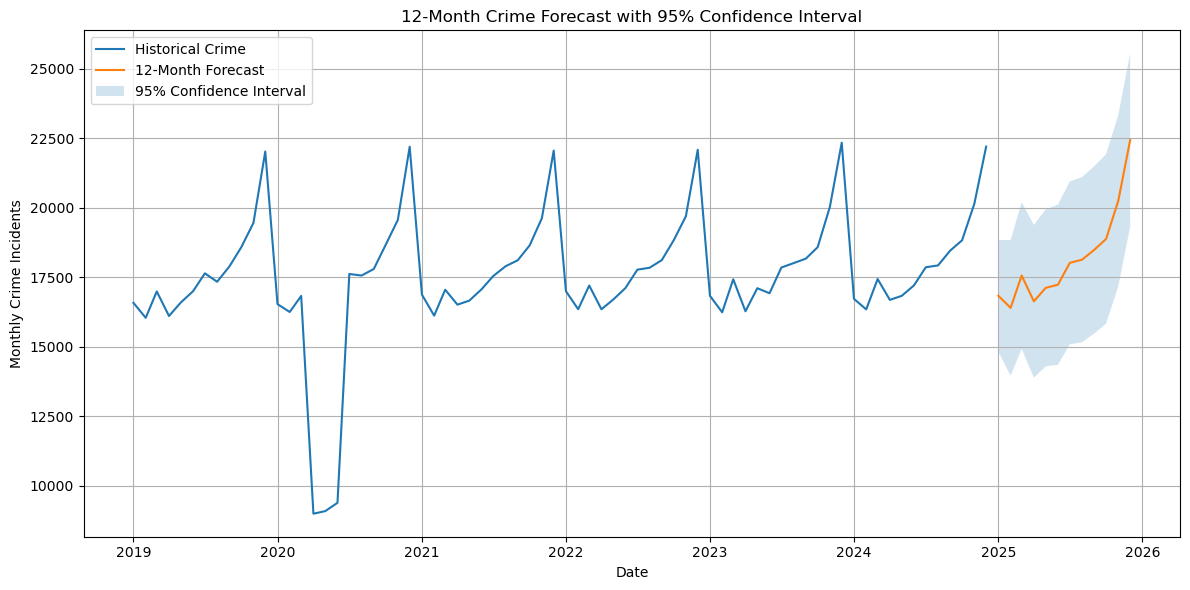

In [203]:
plt.figure(figsize=(12,6))

plt.plot(
    forecast_data.index,
    forecast_data.values,
    label="Historical Crime"
)

plt.plot(
    forecast_mean.index,
    forecast_mean.values,
    label="12-Month Forecast"
)

plt.fill_between(
    forecast_mean.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.xlabel("Date")
plt.ylabel("Monthly Crime Incidents")
plt.title("12-Month Crime Forecast with 95% Confidence Interval")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Forecasting Results and Interpretation

The forecasting analysis used monthly crime incidents from January 2019 to December 2024. The first 60 observations were used to train and evaluate the Holt-Winters model, while the final 12 observations from 2024 were used as a testing period.

The Holt-Winters model achieved a Mean Absolute Error (MAE) of 605.48 incidents and a Root Mean Squared Error (RMSE) of 930.14 incidents on the 2024 test period. These results indicate that the model was able to capture the general pattern in monthly crime incidents, although some forecasting error remained.

After evaluation, the full historical dataset was used to fit a SARIMAX forecasting model. The model was used to generate a 12-month forecast for 2025. A 95% confidence interval was also calculated to represent the uncertainty surrounding the predictions.

The confidence interval provides a range within which the future crime values are expected to fall with approximately 95% confidence under the assumptions of the model. The forecast should therefore be interpreted as an estimate rather than a guaranteed prediction.

Overall, the forecasting analysis provides a data-driven estimate of future monthly crime activity and can support crime-monitoring and resource-planning decisions.


##  Streamlit Dashboard

A Streamlit dashboard will be developed to provide an interactive interface for exploring the crime analytics results. The dashboard will allow users to examine crime patterns, filter the data, view classification results, inspect model performance and access the 12-month crime forecast.

The dashboard is intended to make the machine-learning results accessible to both technical and non-technical users.


In [9]:
import os

print("Current folder:")
print(os.getcwd())

print("\nNotebook files in this folder:")
for file in os.listdir():
    if file.endswith(".ipynb"):
        print(file)

Current folder:
c:\Users\HP\Documents\Crime_Analytics_Project

Notebook files in this folder:
crime_analysis.ipynb


In [10]:
station_clean.to_csv("station_clean.csv", index=False)
crime_clean.to_csv("crime_clean.csv", index=False)

print("Datasets exported successfully.")

NameError: name 'station_clean' is not defined